# Imports

In [ ]:
from loader import *

# Exploratory Data Analysis

In [27]:
outcome = outcome_data.copy()

#Outcome Data Cleaning

def convert_to_days(age_str):
    if pd.isna(age_str) or not isinstance(age_str, str):
        return None
    # Clean up the string (lowercase, remove extra spaces)
    age_str = age_str.lower().strip()
    parts = age_str.split()
    if len(parts) < 2:
        return None
    try:
        num = float(parts[0])
    except ValueError:
        return None
    unit = parts[1]
    if 'year' in unit:
        return num * 365.25 
    elif 'month' in unit:
        return num * 30.44 
    elif 'week' in unit:
        return num * 7
    elif 'day' in unit:
        return num

outcome['DateTime'] = pd.to_datetime(intake_data['DateTime'].str.slice(0, 10))
outcome['Date of Birth'] = pd.to_datetime(outcome['Date of Birth'])
outcome['Age in Days upon Outcome'] = outcome['Age upon Outcome'].apply(convert_to_days)
outcome = outcome[outcome['Age in Days upon Outcome'] >= 0]
outcome = outcome.dropna(subset=['Outcome Type'])
outcome['IsEuthanized'] = outcome['Outcome Type'].apply(lambda x: 1 if x == 'Euthanasia' else 0)
outcome.info()
print(outcome.describe())
outcome.head()



<class 'pandas.DataFrame'>
Index: 173710 entries, 0 to 173774
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Animal ID                 173710 non-null  str           
 1   Date of Birth             173710 non-null  datetime64[us]
 2   Name                      123952 non-null  str           
 3   DateTime                  173710 non-null  datetime64[us]
 4   MonthYear                 173710 non-null  str           
 5   Outcome Type              173710 non-null  str           
 6   Outcome Subtype           79646 non-null   str           
 7   Animal Type               173710 non-null  str           
 8   Sex upon Outcome          173709 non-null  str           
 9   Age upon Outcome          173710 non-null  str           
 10  Breed                     173710 non-null  str           
 11  Color                     173710 non-null  str           
 12  Age in Days upon O

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color,Age in Days upon Outcome,IsEuthanized
0,A668305,2012-12-01,NaN,2013-10-01,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow,365.25,0
1,A673335,2012-02-22,NaN,2013-10-01,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray,730.50,1
2,A675999,2013-04-03,NaN,2013-10-01,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green,365.25,0
4,A680855,2014-05-25,NaN,2013-10-01,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black,14.00,0
5,A680857,2014-05-25,NaN,2013-10-01,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black,14.00,0


Breed
Domestic Shorthair Mix              34039
Domestic Shorthair                  23833
Pit Bull Mix                        10148
Labrador Retriever Mix               8811
Chihuahua Shorthair Mix              6916
                                    ...  
Great Pyrenees/Australian Kelpie        1
Dachshund Longhair/Border Collie        1
Dachshund/Bulldog                       1
Labrador Retriever/Affenpinscher        1
Pekingese/Lhasa Apso                    1
Name: count, Length: 3009, dtype: int64
Sex upon Outcome
Neutered Male    60917
Spayed Female    55251
Intact Male      22253
Intact Female    21799
Unknown          13489
Name: count, dtype: int64


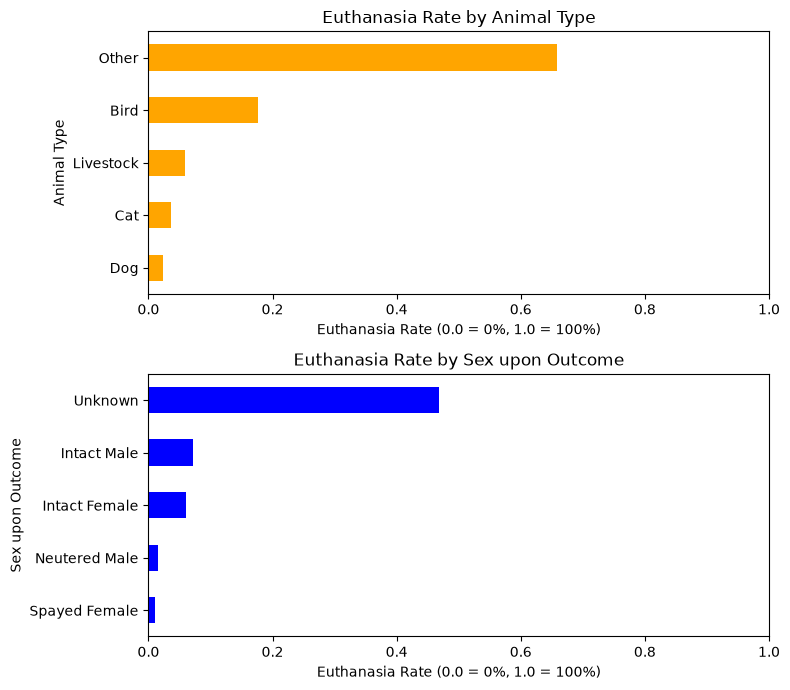

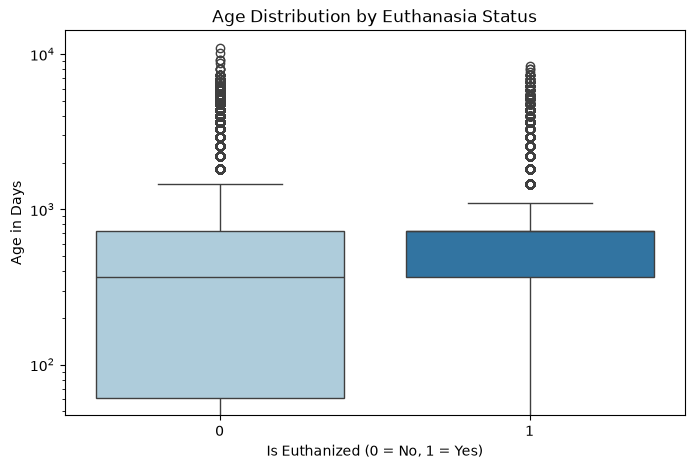

In [38]:
#Animal Type, Sex upon Outcome, Breed, Days upon Outcome

breed_counts = outcome['Breed'].value_counts()
print(breed_counts)
sex_counts = outcome['Sex upon Outcome'].value_counts()
print(sex_counts)


import matplotlib.pyplot as plt
import seaborn as sns

column_name = 'Animal Type'
animaltype_rates = outcome.groupby(column_name)['IsEuthanized'].mean().sort_values()
sex_rates = outcome.groupby('Sex upon Outcome')['IsEuthanized'].mean().sort_values()

# Plot it as a horizontal bar chart
fig, axs = plt.subplots(2, 1, figsize=(8, 7))
animaltype_rates.plot(kind='barh', color='orange', ax=axs[0])
axs[0].set_title(f'Euthanasia Rate by {column_name}')
axs[0].set_xlabel('Euthanasia Rate (0.0 = 0%, 1.0 = 100%)')
axs[0].set_xlim(0, 1)

sex_rates.plot(kind='barh', color='blue', ax=axs[1])
axs[1].set_title(f'Euthanasia Rate by Sex upon Outcome')
axs[1].set_xlabel('Euthanasia Rate (0.0 = 0%, 1.0 = 100%)')
axs[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=outcome, x='IsEuthanized', y='Age in Days upon Outcome', hue = 'IsEuthanized', palette='Paired', legend = False)
plt.title('Age Distribution by Euthanasia Status')
plt.xlabel('Is Euthanized (0 = No, 1 = Yes)')
plt.ylabel('Age in Days')
plt.yscale('log')
plt.show()
